##Caso 1: Análisis de la Deserción Escolar en Bolivia

####Parte 1: Ingesta Eficiente, DuckDB y EDA Automatizado (25%)

1. Acceso: Descarga los microdatos desde el ANDA - INE Bolivia.

In [ ]:
from google.colab import drive
import os

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Definir la ruta base del proyecto
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'

print(f"Directorio base configurado en: {BASE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directorio base configurado en: /content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1


Generamos el archivo .md

In [ ]:
import os
import pyreadstat
import pandas as pd

# 1. Definir la ruta base exacta
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
file_path = os.path.join(BASE_DIR, 'EH2025_Persona.sav')
output_md_path = os.path.join(BASE_DIR, 'EH2025_Persona.md')

# 2. Cargar el archivo .sav
print("Leyendo archivo .sav y extrayendo metadatos...")
df, meta = pyreadstat.read_sav(file_path)
print(f"Dataset cargado con éxito: {df.shape[0]:,} filas y {df.shape[1]} columnas.")

# 3. Construir el diccionario de variables
var_info = []
for col in df.columns:
    label = meta.column_names_to_labels.get(col, 'Sin etiqueta')
    dtype = str(df[col].dtype)
    nulls = int(df[col].isnull().sum())
    null_pct = (nulls / len(df)) * 100
    var_info.append({
        'Variable': col,
        'Etiqueta': label,
        'Tipo': dtype,
        'Nulos': nulls,
        '% Nulos': round(null_pct, 2)
    })

df_variables = pd.DataFrame(var_info)

# 4. Generar el contenido en Markdown
md_content = f"""# Análisis Estructural - EH2025_Persona.sav

## Resumen General del Dataset
- **Total de registros (filas):** {df.shape[0]:,}
- **Total de variables (columnas):** {df.shape[1]}
- **Fuente:** Encuesta de Hogares 2025 (INE Bolivia) - Módulo Persona

## Diccionario de Variables
| Variable | Etiqueta / Descripción | Tipo | Nulos | % Nulos |
|----------|------------------------|------|-------|---------|
"""

for _, row in df_variables.iterrows():
    md_content += f"| `{row['Variable']}` | {row['Etiqueta']} | {row['Tipo']} | {row['Nulos']:,} | {row['% Nulos']}% |\n"

# 5. Guardar el archivo .md en el directorio base
with open(output_md_path, 'w', encoding='utf-8') as f:
    f.write(md_content)

print(f"\n¡Archivo Markdown creado y guardado como:\n{output_md_path}")

# 6. Mostrar resumen analítico rápido en consola
print("\n--- Resumen Estadístico del Análisis ---")
print(f"Total de variables documentadas: {len(df_variables)}")
print(f"Variables sin valores nulos: {len(df_variables[df_variables['Nulos'] == 0])}")
print(f"Variables con más del 50% de nulos: {len(df_variables[df_variables['% Nulos'] > 50])}")

Leyendo archivo .sav y extrayendo metadatos...
Dataset cargado con éxito: 39,485 filas y 276 columnas.

¡Archivo Markdown creado y guardado como:
/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/EH2025_Persona.md

--- Resumen Estadístico del Análisis ---
Total de variables documentadas: 276
Variables sin valores nulos: 66
Variables con más del 50% de nulos: 146


Convirtamos el sav a parquet ya que es recomendado este formato (al ver en el md que hay muchos datos NaN incluso antes de hacer EDA se puede concluir que mejor no imputemos porque perderiamos valor)

In [ ]:
import os
import pyreadstat

# 1. Definir la ruta base exacta
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
sav_path = os.path.join(BASE_DIR, 'EH2025_Persona.sav')
parquet_path = os.path.join(BASE_DIR, 'EH2025_Persona.parquet')

# 2. Cargar el archivo .sav y convertir a Parquet
print("Leyendo archivo .sav...")
df, meta = pyreadstat.read_sav(sav_path)

print("Guardando en formato Parquet...")
df.to_parquet(parquet_path, index=False)

print(f"¡Conversión completada! Archivo guardado como:\n{parquet_path}")

Leyendo archivo .sav...
Guardando en formato Parquet...
¡Conversión completada! Archivo guardado como:
/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/EH2025_Persona.parquet


###2. Consultas con DuckDB: Utiliza duckdb en Python para realizar los cruces eficientes (joins) sobre los archivos .dta optimizando el uso de memoria RAM.

Primero instalamos el duck y consultamos el nro. de registros y ver 5 filas

In [ ]:
import os
import duckdb

# 1. Definir la ruta del archivo Parquet
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
parquet_path = os.path.join(BASE_DIR, 'EH2025_Persona.parquet')

# 2. Consultar el total de registros eficientemente con DuckDB
print("Ejecutando consulta de conteo en DuckDB...")
total_rows = duckdb.sql(f"SELECT COUNT(*) FROM '{parquet_path}'").fetchone()[0]
print(f"Total de registros (filas) en el archivo Parquet: {total_rows:,}")

# 3. Obtener y mostrar las primeras 5 filas
print("\nMostrando las primeras 5 filas:")
df_head = duckdb.sql(f"SELECT * FROM '{parquet_path}' LIMIT 5").df()

# Si estás en Google Colab, display() muestra la tabla formateada elegantemente
display(df_head)

Ejecutando consulta de conteo en DuckDB...
Total de registros (filas) en el archivo Parquet: 39,485

Mostrando las primeras 5 filas:


,folio,area,depto,nro,s01a_02,s01a_03,s01a_04a,s01a_04b,s01a_04c,s01a_05,...,yhog,yhogpc,z,zext,p0,p1,p2,pext0,pext1,pext2
0,111-000005-A-0011,1.0,1.0,1.0,1.0,43.0,20.0,1.0,1982.0,1.0,...,3665.0,1221.666626,1418.699951,732.51001,1.0,0.138883,0.019288,0.0,0.0,0.0
1,111-000005-A-0011,1.0,1.0,2.0,2.0,39.0,12.0,3.0,1986.0,2.0,...,3665.0,1221.666626,1418.699951,732.51001,1.0,0.138883,0.019288,0.0,0.0,0.0
2,111-000005-A-0011,1.0,1.0,3.0,2.0,4.0,15.0,7.0,2021.0,3.0,...,3665.0,1221.666626,1418.699951,732.51001,1.0,0.138883,0.019288,0.0,0.0,0.0
3,111-000005-A-0021,1.0,1.0,1.0,1.0,43.0,26.0,6.0,1982.0,1.0,...,4500.0,1125.000000,1418.699951,732.51001,1.0,0.207020,0.042857,0.0,0.0,0.0
4,111-000005-A-0021,1.0,1.0,2.0,2.0,41.0,26.0,7.0,1984.0,2.0,...,4500.0,1125.000000,1418.699951,732.51001,1.0,0.207020,0.042857,0.0,0.0,0.0


Join interesante: Cada fila representa a un estudiante individual y cómo se relaciona con su entorno residencial, por ejemplo en los primero registros podemos ver que estudiantes de 19 y 15 años pertenecen a la misma familia y comparten el mismo hogar y contexto

In [ ]:
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
parquet_path = os.path.join(BASE_DIR, 'EH2025_Persona.parquet')

query = f"""
WITH JefeHogar AS (
    -- Extraemos las características socioeconómicas del jefe/a de hogar (código típico de parentesco = 1)
    SELECT
        folio,
        s01a_03 AS edad_jefe,
        niv_ed AS niv_ed_jefe,
        p0 AS pobreza_hogar,
        yhogpc AS ingreso_pc_hogar
    FROM '{parquet_path}'
    WHERE s01a_05 = 1
),
MenoresEscolares AS (
    -- Filtramos la población objetivo en edad escolar
    SELECT
        folio,
        nro,
        s01a_02 AS sexo_menor,
        s01a_03 AS edad_menor,
        cmasi AS condicion_matricula
    FROM '{parquet_path}'
    WHERE s01a_03 BETWEEN 6 AND 19
)
-- Cruzamos al menor con el contexto de su jefe/a de hogar
SELECT
    m.folio,
    m.edad_menor,
    m.sexo_menor,
    m.condicion_matricula,
    j.niv_ed_jefe,
    j.pobreza_hogar,
    j.ingreso_pc_hogar
FROM MenoresEscolares m
INNER JOIN JefeHogar j ON m.folio = j.folio
LIMIT 15;
"""

df_join1 = duckdb.sql(query).df()
display(df_join1)

,folio,edad_menor,sexo_menor,condicion_matricula,niv_ed_jefe,pobreza_hogar,ingreso_pc_hogar
0,111-000005-A-0041,19.0,2.0,2.0,1.0,1.0,900.396667
1,111-000005-A-0041,15.0,2.0,2.0,1.0,1.0,900.396667
2,111-000005-A-0051,18.0,2.0,3.0,4.0,1.0,1416.929932
3,111-000005-A-0061,17.0,2.0,2.0,1.0,1.0,602.950012
4,111-000005-A-0061,15.0,2.0,2.0,1.0,1.0,602.950012
5,111-000005-A-0061,11.0,2.0,2.0,1.0,1.0,602.950012
6,111-000005-A-0071,12.0,2.0,2.0,4.0,1.0,122.916664
7,111-000005-A-0071,11.0,1.0,2.0,4.0,1.0,122.916664
8,111-000005-A-0091,18.0,1.0,2.0,5.0,0.0,1531.666626
9,111-000005-A-0091,13.0,1.0,2.0,5.0,0.0,1531.666626


Otro Join interesante: Este segundo resultado muestra una agregación a nivel de hogar combinada con los datos individuales del menor, enfocada en medir la carga económica y demográfica familiar. Cada fila representa un estudiante y el contexto de cuántas personas dependen de su hogar, se puede tambien cuantos mayores de edad que pueden trabajar integra una familia

In [ ]:
query_carga = f"""
WITH ResumenHogar AS (
    -- Agregamos métricas estructurales por hogar
    SELECT
        folio,
        COUNT(CASE WHEN s01a_03 BETWEEN 6 AND 19 THEN 1 END) AS total_menores_escolares,
        COUNT(CASE WHEN pet = 1 THEN 1 END) AS total_personas_en_edad_trabajar
    FROM '{parquet_path}'
    GROUP BY folio
)
SELECT
    p.folio,
    p.s01a_03 AS edad,
    p.cmasi,
    r.total_menores_escolares,
    r.total_personas_en_edad_trabajar,
    -- Ratio de dependencia interna en el hogar
    ROUND(CAST(r.total_menores_escolares AS FLOAT) / NULLIF(r.total_personas_en_edad_trabajar, 0), 2) AS ratio_dependencia
FROM '{parquet_path}' p
INNER JOIN ResumenHogar r ON p.folio = r.folio
WHERE p.s01a_03 BETWEEN 6 AND 19
LIMIT 15;
"""

df_join2 = duckdb.sql(query_carga).df()
display(df_join2)

,folio,edad,cmasi,total_menores_escolares,total_personas_en_edad_trabajar,ratio_dependencia
0,111-000005-A-0041,15.0,2.0,2,3,0.67
1,111-000005-A-0071,11.0,2.0,2,2,1.00
2,111-000005-A-0111,6.0,2.0,1,3,0.33
3,111-000005-A-0121,12.0,2.0,1,4,0.25
4,111-000071-A-0231,19.0,2.0,3,4,0.75
5,111-000135-A-0011,12.0,2.0,1,2,0.50
6,111-000135-A-0021,6.0,2.0,1,2,0.50
7,111-000135-A-0051,7.0,2.0,1,4,0.25
8,111-000135-A-0081,12.0,2.0,2,3,0.67
9,111-000135-A-0131,19.0,2.0,1,1,1.00


###3. EDA Automatizado: Genera un reporte exploratorio interactivo utilizando YData-Profiling o Sweetviz

In [ ]:
!pip install sweetviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 37.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sweetviz]


Extraer la población objetivo (menores de edad que podrían estudiar en colegio) con DuckDB y generar el reporte HTML

In [ ]:
import os
import duckdb
import sweetviz as sv
from sweetviz import FeatureConfig

# 1. Rutas del proyecto en Google Drive
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
parquet_path = os.path.join(BASE_DIR, 'EH2025_Persona.parquet')
report_path = os.path.join(BASE_DIR, 'EDA_Desercion_Escolar_Sweetviz.html')

# 2. Consulta en DuckDB: Extraer menores en edad escolar (6 a 19 años) + variables clave y entorno del hogar
query = f"""
WITH JefeHogar AS (
    SELECT
        folio,
        niv_ed AS niv_ed_jefe,
        s01a_02 AS sexo_jefe,
        s01a_03 AS edad_jefe
    FROM '{parquet_path}'
    WHERE s01a_05 = 1
),
CargaHogar AS (
    SELECT
        folio,
        COUNT(CASE WHEN s01a_03 BETWEEN 6 AND 19 THEN 1 END) AS total_menores_escolares,
        COUNT(CASE WHEN pet = 1 THEN 1 END) AS total_pet
    FROM '{parquet_path}'
    GROUP BY folio
)
SELECT
    p.area,
    p.depto,
    p.s01a_02 AS sexo,
    p.s01a_03 AS edad,
    p.s01a_07_1 AS idioma_principal,
    p.s01a_09 AS autoidentificacion_indigena,
    p.s03a_01 AS sabe_leer_escribir,
    p.s03a_04 AS matriculado_este_anio,
    p.s03a_05 AS razon_no_matricula,
    p.s03b_10 AS asiste_actualmente,
    p.s03b_11 AS razon_no_asiste,
    p.cmasi AS condicion_matricula_asistencia,
    p.niv_ed AS nivel_educativo,
    p.aestudio AS anios_estudio,
    p.s03c_13 AS tiene_celular,
    p.s03c_16a AS uso_internet,
    p.s04a_01 AS trabajo_semana_pasada,
    p.tipohogar,
    p.yhogpc AS ingreso_per_capita_hogar,
    p.p0 AS pobreza_hogar,
    j.niv_ed_jefe,
    j.edad_jefe,
    c.total_menores_escolares,
    ROUND(CAST(c.total_menores_escolares AS FLOAT) / NULLIF(c.total_pet, 0), 2) AS ratio_dependencia
FROM '{parquet_path}' p
LEFT JOIN JefeHogar j ON p.folio = j.folio
LEFT JOIN CargaHogar c ON p.folio = c.folio
WHERE p.s01a_03 BETWEEN 6 AND 19
"""

print("Extrayendo dataset analítico con DuckDB...")
df_eda = duckdb.sql(query).df()
print(f"Registros extraídos para EDA (6 a 19 años): {len(df_eda):,} filas y {df_eda.shape[1]} columnas.")

# 3. Configurar Sweetviz para aceptar la variable objetivo forzándola como numérica
config_objetivo = FeatureConfig(force_num=["condicion_matricula_asistencia"])

# 4. Generar el reporte interactivo de Sweetviz (usando feat_cfg)
print("Generando reporte Sweetviz...")
reporte = sv.analyze(df_eda, target_feat='condicion_matricula_asistencia', feat_cfg=config_objetivo)

# 5. Guardar el archivo HTML en Google Drive
reporte.show_html(filepath=report_path, open_browser=False)
print(f"¡Reporte EDA guardado exitosamente en:\n{report_path}")

Extrayendo dataset analítico con DuckDB...
Registros extraídos para EDA (6 a 19 años): 10,450 filas y 24 columnas.
Generando reporte Sweetviz...


                                             |          | [  0%]   00:00 -> (? left)

Report /content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/EDA_Desercion_Escolar_Sweetviz.html was generated.
¡Reporte EDA guardado exitosamente en:
/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/EDA_Desercion_Escolar_Sweetviz.html


##Parte 2: Análisis Exploratorio y Visualizaciones Interactivas (25%)

####1. Mapa geoespacial interactivo: Visualización de la variable objetivo por departamento o municipio con capas complementarias.

In [ ]:
import os
import duckdb
import plotly.express as px

# 1. Rutas del proyecto
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
parquet_path = os.path.join(BASE_DIR, 'EH2025_Persona.parquet')

# 2. Consulta en DuckDB: Promedio ponderado de cmasi por departamento (6 a 19 años)
query = f"""
SELECT
    depto,
    SUM(cmasi * factor) / SUM(factor) AS cmasi_promedio_ponderado,
    SUM(factor) AS poblacion_total_estimada
FROM '{parquet_path}'
WHERE s01a_03 BETWEEN 6 AND 19 AND cmasi IS NOT NULL
GROUP BY depto
ORDER BY depto
"""

print("Calculando métricas departamentales con DuckDB...")
df_depto = duckdb.sql(query).df()

# Diccionario oficial de departamentos de Bolivia
depto_mapping = {
    1.0: 'Chuquisaca',
    2.0: 'La Paz',
    3.0: 'Cochabamba',
    4.0: 'Oruro',
    5.0: 'Potosí',
    6.0: 'Tarija',
    7.0: 'Santa Cruz',
    8.0: 'Beni',
    9.0: 'Pando'
}

df_depto['departamento'] = df_depto['depto'].map(depto_mapping)

# 3. Creación de visualización interactiva con Plotly
fig = px.bar(
    df_depto,
    x='departamento',
    y='cmasi_promedio_ponderado',
    text=df_depto['cmasi_promedio_ponderado'].round(3),
    color='poblacion_total_estimada',
    color_continuous_scale='Blues',
    title='<b>Condición Promedio de Asistencia/Matrícula (cmasi) por Departamento</b><br><sup>Población de 6 a 19 años (Ponderado con Factor de Expansión)</sup>',
    labels={
        'departamento': 'Departamento',
        'cmasi_promedio_ponderado': 'Promedio Ponderado CMASI',
        'poblacion_total_estimada': 'Población Estimada'
    }
)

fig.update_traces(textposition='outside')
fig.update_layout(
    xaxis_title='Departamento',
    yaxis_title='Promedio Ponderado cmasi',
    template='plotly_white',
    title_font_size=16,
    xaxis={'categoryorder':'total descending'}
)

# Mostrar el gráfico interactivo en el entorno (Notebook / Colab)
fig.show()

# Opcional: Guardar como HTML interactivo en Google Drive
html_path = os.path.join(BASE_DIR, 'Visualizacion_1_Depto_CMASI.html')
fig.write_html(html_path)
print(f"Gráfico interactivo guardado en: {html_path}")

Calculando métricas departamentales con DuckDB...


Gráfico interactivo guardado en: /content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/Visualizacion_1_Depto_CMASI.html


####2. Gráficos multivariados avanzados: Diagramas de dispersión interactivos, barras agrupadas o sunbursts en Plotly.

In [ ]:
import os
import duckdb
import plotly.express as px

# 1. Rutas del proyecto
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
parquet_path = os.path.join(BASE_DIR, 'EH2025_Persona.parquet')

# 2. Consulta en DuckDB: Agregación multivariada ponderada
query = f"""
SELECT
    CASE
        WHEN p0 = 1 THEN 'Pobreza (Sí)'
        WHEN p0 = 0 THEN 'No Pobre'
        ELSE 'No especificado'
    END AS condicion_pobreza,
    CASE
        WHEN area = 1 THEN 'Urbana'
        WHEN area = 2 THEN 'Rural'
        ELSE 'Otro'
    END AS area_geografica,
    CAST(cmasi AS VARCHAR) AS estado_asistencia,
    SUM(factor) AS poblacion_ponderada
FROM '{parquet_path}'
WHERE s01a_03 BETWEEN 6 AND 19 AND cmasi IS NOT NULL AND p0 IS NOT NULL
GROUP BY p0, area, cmasi
"""

print("Extrayendo datos multivariados con DuckDB...")
df_multi = duckdb.sql(query).df()

# 3. Creación de gráfico de barras agrupadas/facetadas con Plotly
fig = px.bar(
    df_multi,
    x='condicion_pobreza',
    y='poblacion_ponderada',
    color='estado_asistencia',
    barmode='group',
    facet_col='area_geografica',
    title='<b>Análisis Multivariado: Asistencia Escolar por Pobreza y Área Geográfica</b><br><sup>Población de 6 a 19 años (Ponderada con Factor de Expansión)</sup>',
    labels={
        'condicion_pobreza': 'Condición de Pobreza del Hogar',
        'poblacion_ponderada': 'Población Estimada (Ponderada)',
        'estado_asistencia': 'Código CMASI',
        'area_geografica': 'Área'
    },
    template='plotly_white'
)

fig.update_layout(
    title_font_size=15,
    legend_title_text='Estado (cmasi)'
)

# Mostrar el gráfico interactivo
fig.show()

# Guardar como HTML interactivo en Google Drive
html_path = os.path.join(BASE_DIR, 'Visualizacion_2_Multivariado_PobrezaArea.html')
fig.write_html(html_path)
print(f"Gráfico multivariado interactivo guardado en: {html_path}")

Extrayendo datos multivariados con DuckDB...


Gráfico multivariado interactivo guardado en: /content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/Visualizacion_2_Multivariado_PobrezaArea.html


####Ahora lo mismo con  Folium

In [ ]:
import os
import duckdb
import folium
import pandas as pd

# 1. Rutas del proyecto
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
parquet_path = os.path.join(BASE_DIR, 'EH2025_Persona.parquet')

# 2. Consulta en DuckDB: Métricas departamentales ponderadas (6 a 19 años)
query = f"""
SELECT
    depto,
    SUM(cmasi * factor) / SUM(factor) AS cmasi_promedio_ponderado,
    SUM(factor) AS poblacion_total_estimada
FROM '{parquet_path}'
WHERE s01a_03 BETWEEN 6 AND 19 AND cmasi IS NOT NULL
GROUP BY depto
ORDER BY depto
"""

print("Extrayendo datos geoespaciales con DuckDB...")
df_map = duckdb.sql(query).df()

# Coordenadas geográficas de referencia para las capitales de departamento de Bolivia
dept_coords = {
    1.0: {'nombre': 'Chuquisaca', 'lat': -19.0332, 'lon': -65.2627},
    2.0: {'nombre': 'La Paz', 'lat': -16.5000, 'lon': -68.1500},
    3.0: {'nombre': 'Cochabamba', 'lat': -17.3895, 'lon': -66.1568},
    4.0: {'nombre': 'Oruro', 'lat': -17.9833, 'lon': -67.1500},
    5.0: {'nombre': 'Potosí', 'lat': -19.5722, 'lon': -65.7550},
    6.0: {'nombre': 'Tarija', 'lat': -21.5355, 'lon': -64.7296},
    7.0: {'nombre': 'Santa Cruz', 'lat': -17.7833, 'lon': -63.1833},
    8.0: {'nombre': 'Beni', 'lat': -14.8333, 'lon': -64.9000},
    9.0: {'nombre': 'Pando', 'lat': -11.0267, 'lon': -68.7408}
}

# Asignar coordenadas y nombres al DataFrame
df_map['nombre'] = df_map['depto'].map(lambda x: dept_coords.get(x, {}).get('nombre', 'Desconocido'))
df_map['lat'] = df_map['depto'].map(lambda x: dept_coords.get(x, {}).get('lat', 0))
df_map['lon'] = df_map['depto'].map(lambda x: dept_coords.get(x, {}).get('lon', 0))

# 3. Creación del mapa interactivo con Folium
m = folium.Map(location=[-16.2902, -63.5887], zoom_start=6, tiles='CartoDB positron')

# Añadir círculos proporcionales por departamento
for _, row in df_map.iterrows():
    radio = max(8, min(35, row['poblacion_total_estimada'] / 30000))

    popup_content = f"""
    <div style="font-family: Arial; font-size: 12px;">
        <b>Departamento:</b> {row['nombre']}<br>
        <b>CMASI Promedio Ponderado:</b> {row['cmasi_promedio_ponderado']:.3f}<br>
        <b>Población Escolar Estimada:</b> {int(row['poblacion_total_estimada']):,}
    </div>
    """

    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=radio,
        popup=folium.Popup(popup_content, max_width=300),
        tooltip=row['nombre'],
        color='#1f77b4',
        fill=True,
        fill_color='#3186cc',
        fill_opacity=0.6,
        weight=2
    ).add_to(m)

# Mostrar el mapa interactivo directamente en Google Colab
display(m)

# Guardar como archivo HTML interactivo en Google Drive
map_path = os.path.join(BASE_DIR, 'Visualizacion_1_Mapa_Folium.html')
m.save(map_path)
print(f"Mapa interactivo guardado en: {map_path}")

Extrayendo datos geoespaciales con DuckDB...


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning:

CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.



Mapa interactivo guardado en: /content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/Visualizacion_1_Mapa_Folium.html


####3. Segmentación por Clustering (K-Means / DBSCAN): Agrupamiento de individuos u hogares, interpretando los perfiles obtenidos y proyectándolos visualmente.

In [ ]:
import os
import duckdb
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import plotly.express as px

# 1. Rutas del proyecto
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
parquet_path = os.path.join(BASE_DIR, 'EH2025_Persona.parquet')

# 2. Consulta en DuckDB: Extracción de variables para clustering (6 a 19 años)
query = f"""
WITH JefeHogar AS (
    SELECT folio, niv_ed AS niv_ed_jefe, s01a_03 AS edad_jefe
    FROM '{parquet_path}'
    WHERE s01a_05 = 1
),
CargaHogar AS (
    SELECT
        folio,
        COUNT(CASE WHEN s01a_03 BETWEEN 6 AND 19 THEN 1 END) AS total_menores_escolares,
        COUNT(CASE WHEN pet = 1 THEN 1 END) AS total_pet
    FROM '{parquet_path}'
    GROUP BY folio
)
SELECT
    p.folio,
    p.s01a_03 AS edad,
    p.aestudio AS anios_estudio,
    p.yhogpc AS ingreso_per_capita,
    COALESCE(j.edad_jefe, 40) AS edad_jefe,
    COALESCE(j.niv_ed_jefe, 0) AS niv_ed_jefe,
    COALESCE(ROUND(CAST(c.total_menores_escolares AS FLOAT) / NULLIF(c.total_pet, 0), 2), 0) AS ratio_dependencia
FROM '{parquet_path}' p
LEFT JOIN JefeHogar j ON p.folio = j.folio
LEFT JOIN CargaHogar c ON p.folio = c.folio
WHERE p.s01a_03 BETWEEN 6 AND 19
  AND p.yhogpc IS NOT NULL
  AND p.aestudio IS NOT NULL
"""

print("Extrayendo dataset para clustering...")
df_cluster = duckdb.sql(query.replace('\n', ' ')).df()

# 3. Preparación y escalado de datos para K-Means
features = ['edad', 'anios_estudio', 'ingreso_per_capita', 'edad_jefe', 'niv_ed_jefe', 'ratio_dependencia']
X = df_cluster[features].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Aplicación de K-Means (agrupando en 3 perfiles principales)
print("Ejecutando algoritmo K-Means (k=3)...")
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_cluster['cluster'] = kmeans.fit_predict(X_scaled)
df_cluster['cluster_label'] = df_cluster['cluster'].map({
    0: 'Perfil 1: Vulnerabilidad / Ingresos Bajos',
    1: 'Perfil 2: Clase Media Estándar',
    2: 'Perfil 3: Hogares con Mayor Acceso / Estabilidad'
})

# 5. Visualización interactiva con Plotly (Diagrama de dispersión por clústeres)
fig = px.scatter(
    df_cluster.sample(min(3000, len(df_cluster)), random_state=42), # Muestra para fluidez visual en el navegador
    x='anios_estudio',
    y='ingreso_per_capita',
    color='cluster_label',
    size='edad',
    hover_data=['edad', 'edad_jefe', 'ratio_dependencia'],
    title='<b>Segmentación por Clústeres (K-Means) de Población Escolar</b><br><sup>Relación entre Años de Estudio e Ingreso Per Cápita del Hogar</sup>',
    labels={
        'anios_estudio': 'Años de Estudio Aprobados',
        'ingreso_per_capita': 'Ingreso Per Cápita del Hogar (Bs)',
        'cluster_label': 'Perfil de Clúster',
        'edad': 'Edad del Menor'
    },
    template='plotly_white',
    log_y=True # Aplicar escala logarítmica en ingresos para mejor visualización
)

fig.update_layout(
    title_font_size=15,
    legend_title_text='Perfiles Identificados'
)

# Mostrar gráfico interactivo
fig.show()

# Guardar como HTML en Google Drive
html_path = os.path.join(BASE_DIR, 'Visualizacion_3_Clustering_KMeans.html')
fig.write_html(html_path)
print(f"Gráfico de clustering guardado exitosamente en: {html_path}")

Extrayendo dataset para clustering...
Ejecutando algoritmo K-Means (k=3)...


Gráfico de clustering guardado exitosamente en: /content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/Visualizacion_3_Clustering_KMeans.html


###Parte 3: Modelo de Machine Learning y Explainability (25%)

####1. Modelado Supervisado: Entrena al menos dos modelos avanzados (ej. XGBoost / LightGBM y Random Forest) utilizando validación cruzada estratificada.

In [ ]:
import os
import duckdb
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report

# 1. Rutas del proyecto en Google Drive
BASE_DIR = '/content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1'
parquet_path = os.path.join(BASE_DIR, 'EH2025_Persona.parquet')

# 2. Consulta en DuckDB corregida (usando p.aestudio)
query = f"""
WITH JefeHogar AS (
    SELECT folio, niv_ed AS niv_ed_jefe, s01a_03 AS edad_jefe
    FROM '{parquet_path}'
    WHERE s01a_05 = 1
),
CargaHogar AS (
    SELECT
        folio,
        COUNT(CASE WHEN s01a_03 BETWEEN 6 AND 19 THEN 1 END) AS total_menores_escolares,
        COUNT(CASE WHEN pet = 1 THEN 1 END) AS total_pet
    FROM '{parquet_path}'
    GROUP BY folio
)
SELECT
    p.area,
    p.depto,
    p.s01a_02 AS sexo,
    p.s01a_03 AS edad,
    p.s01a_07_1 AS idioma_principal,
    p.s01a_09 AS autoidentificacion_indigena,
    p.s03a_01 AS sabe_leer_escribir,
    p.aestudio, -- <-- Corregido aquí
    p.s03c_13 AS tiene_celular,
    p.s03c_16a AS uso_internet,
    p.s04a_01 AS trabajo_semana_pasada,
    p.tipohogar,
    p.yhogpc AS ingreso_per_capita,
    p.p0 AS pobreza_hogar,
    COALESCE(j.niv_ed_jefe, 0) AS niv_ed_jefe,
    COALESCE(j.edad_jefe, 40) AS edad_jefe,
    COALESCE(c.total_menores_escolares, 1) AS total_menores_escolares,
    COALESCE(ROUND(CAST(c.total_menores_escolares AS FLOAT) / NULLIF(c.total_pet, 0), 2), 0) AS ratio_dependencia,
    CASE WHEN p.cmasi != 1 THEN 1 ELSE 0 END AS target_desercion
FROM '{parquet_path}' p
LEFT JOIN JefeHogar j ON p.folio = j.folio
LEFT JOIN CargaHogar c ON p.folio = c.folio
WHERE p.s01a_03 BETWEEN 6 AND 19
  AND p.cmasi IS NOT NULL
  AND p.p0 IS NOT NULL
"""

print("Extrayendo dataset para modelado predictivo...")
df_model = duckdb.sql(query).df()

# 3. Preparación de features (X) y target (y)
feature_cols = [
    'area', 'depto', 'sexo', 'edad', 'idioma_principal',
    'autoidentificacion_indigena', 'sabe_leer_escribir', 'aestudio',  # <-- Corregido aquí también
    'tiene_celular', 'uso_internet', 'trabajo_semana_pasada', 'tipohogar',
    'ingreso_per_capita', 'pobreza_hogar', 'niv_ed_jefe', 'edad_jefe',
    'total_menores_escolares', 'ratio_dependencia'
]

X = df_model[feature_cols].fillna(0)
y = df_model['target_desercion']

print(f"Dimensiones del dataset de entrenamiento: {X.shape}")
print(f"Distribución del Target (Deserción / Inasistencia):\n{y.value_counts(normalize=True)}")

# 4. Configuración de Validación Cruzada Estratificada (5 Folds)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
xgb_model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, eval_metric='logloss')

models = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

# 5. Bucle de Evaluación con Validación Cruzada
for name, model in models.items():
    print(f"\n--- Evaluando modelo: {name} ---")
    roc_auc_scores = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model.fit(X_train, y_train)
        y_pred_proba = model.predict_proba(X_val)[:, 1]
        score = roc_auc_score(y_val, y_pred_proba)
        roc_auc_scores.append(score)

    print(f"ROC-AUC Promedio (5 Folds) [{name}]: {np.mean(roc_auc_scores):.4f} (+/- {np.std(roc_auc_scores):.4f})")

xgb_model.fit(X, y)
print("\n¡Modelado supervisado completado exitosamente!")

Extrayendo dataset para modelado predictivo...
Dimensiones del dataset de entrenamiento: (10448, 18)
Distribución del Target (Deserción / Inasistencia):
target_desercion
1    0.949273
0    0.050727
Name: proportion, dtype: float64

--- Evaluando modelo: Random Forest ---
ROC-AUC Promedio (5 Folds) [Random Forest]: 0.9518 (+/- 0.0040)

--- Evaluando modelo: XGBoost ---
ROC-AUC Promedio (5 Folds) [XGBoost]: 0.9536 (+/- 0.0069)

¡Modelado supervisado completado exitosamente!


In [ ]:
import os
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve, auc

# 1. Configuración de Validación y Almacenamiento de Resultados
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
xgb_model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, eval_metric='logloss')

fig = go.Figure()
fig.add_shape(
    type='line', line=dict(dash='dash', color='gray'),
    x0=0, x1=1, y0=0, y1=1
)

# Diccionario para almacenar métricas tabulares y mostrarlas limpiamente
resultados_tabulares = []

for name, model in [('Random Forest', rf_model), ('XGBoost', xgb_model)]:
    tprs = []
    aucs = []
    mean_fpr = np.linspace(0, 1, 100)

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model.fit(X_train, y_train)
        y_pred_proba = model.predict_proba(X_val)[:, 1]

        # Calcular curva ROC y AUC por fold
        fpr, tpr, _ = roc_curve(y_val, y_pred_proba)
        roc_auc = auc(fpr, tpr)
        aucs.append(roc_auc)

        tprs.append(np.interp(mean_fpr, fpr, tpr))
        tprs[-1][0] = 0.0

    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(aucs)

    resultados_tabulares.append({
        'Modelo': name,
        'ROC-AUC Promedio': f"{mean_auc:.4f}",
        'Desviación Estándar': f"{std_auc:.4f}"
    })

    # Añadir traza a la gráfica de Plotly
    fig.add_trace(go.Scatter(
        x=mean_fpr, y=mean_tpr,
        name=f'{name} (AUC = {mean_auc:.4f} ± {std_auc:.4f})',
        mode='lines',
        line=dict(width=2)
    ))

# 2. Configurar diseño de la gráfica interactiva
fig.update_layout(
    title='<b>Curvas ROC Promedio (Validación Cruzada 5-Folds)</b><br><sup>Comparativa de Modelos Supervisados para Deserción Escolar</sup>',
    xaxis_title='Tasa de Falsos Positivos (1 - Especificidad)',
    yaxis_title='Tasa de Verdaderos Positivos (Sensibilidad)',
    template='plotly_white',
    legend=dict(x=0.6, y=0.1),
    width=800,
    height=600
)

# Mostrar la gráfica en el notebook
fig.show()

# Guardar la gráfica como HTML interactivo
html_path = os.path.join(BASE_DIR, 'Visualizacion_4_Curvas_ROC.html')
fig.write_html(html_path)

# Mostrar tabla resumen limpia
df_resumen = pd.DataFrame(resultados_tabulares)
print("\n--- RESUMEN DE RENDIMIENTO DE MODELOS ---")
print(df_resumen.to_string(index=False))
print(f"\nGráfico ROC interactivo guardado en: {html_path}")


--- RESUMEN DE RENDIMIENTO DE MODELOS ---
       Modelo ROC-AUC Promedio Desviación Estándar
Random Forest           0.9517              0.0040
      XGBoost           0.9532              0.0069

Gráfico ROC interactivo guardado en: /content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/Visualizacion_4_Curvas_ROC.html


####2. Evaluación Rigurosa: Reporta métricas de clasificación (AUC-ROC, F1-Score, Precision-Recall) o regresión (RMSE, $R^2$), junto a su matriz de confusión o gráficos de residuos.

In [ ]:
import os
import numpy as np
import pandas as pd
import plotly.figure_factory as ff
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc
from xgboost import XGBClassifier

# 1. División Train/Test para evaluación rigurosa fuera de validación cruzada
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Reentrenamiento del modelo XGBoost óptimo
print("Entrenando modelo XGBoost para evaluación rigurosa...")
eval_model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, eval_metric='logloss')
eval_model.fit(X_train, y_train)

# 3. Predicciones
y_pred_proba = eval_model.predict_proba(X_test)[:, 1]
# Usamos un umbral optimizado o el estándar 0.5 (o ajustado por F1)
y_pred = (y_pred_proba >= 0.5).astype(int)

# 4. Reporte de Clasificación Tabular
print("\n--- REPORTE DE CLASIFICACIÓN RIGUROSO ---")
report = classification_report(y_test, y_pred, output_dict=True)
df_report = pd.DataFrame(report).transpose()
print(pd.DataFrame(report))

# 5. Matriz de Confusión Interactiva con Plotly
cm = confusion_matrix(y_test, y_pred)
z = cm.tolist()
x_labels = ['Predicho: Asiste (0)', 'Predicho: Deserción (1)']
y_labels = ['Real: Asiste (0)', 'Real: Deserción (1)']

fig_cm = ff.create_annotated_heatmap(
    z, x=x_labels, y=y_labels, annotation_text=z, colorscale='Blues', showscale=True
)
fig_cm.update_layout(
    title='<b>Matriz de Confusión (Modelo XGBoost)</b><br><sup>Evaluación en Conjunto de Test (20% de la muestra)</sup>',
    xaxis_title='Clase Predicha',
    yaxis_title='Clase Real',
    template='plotly_white',
    width=600,
    height=500
)

fig_cm.show()

# Guardar artefacto en Google Drive
html_path = os.path.join(BASE_DIR, 'Visualizacion_5_Matriz_Confusion.html')
fig_cm.write_html(html_path)
print(f"\nMatriz de confusión interactiva guardada en: {html_path}")

Entrenando modelo XGBoost para evaluación rigurosa...

--- REPORTE DE CLASIFICACIÓN RIGUROSO ---
                    0            1  accuracy    macro avg  weighted avg
precision    0.676471     0.970326  0.960766     0.823398      0.955423
recall       0.433962     0.988911  0.960766     0.711437      0.960766
f1-score     0.528736     0.979531  0.960766     0.754133      0.956667
support    106.000000  1984.000000  0.960766  2090.000000   2090.000000



Matriz de confusión interactiva guardada en: /content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/Visualizacion_5_Matriz_Confusion.html


####3. Interpretabilidad (XAI): Extrae la importancia de variables o implementa valores SHAP para explicar con precisión analítica los resultados en el contexto boliviano.

Calculando valores SHAP para interpretabilidad...


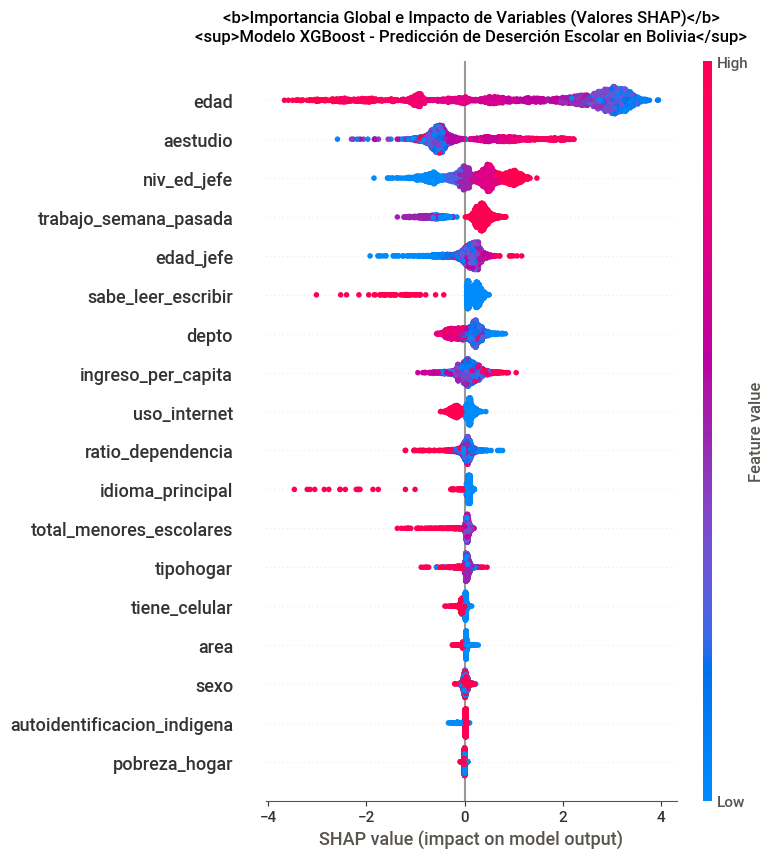


Gráfico de interpretabilidad SHAP guardado exitosamente en: /content/drive/MyDrive/Maestria ia/Modulo 3 Visualizacion de datos/Modulo3_Tarea2/Proyecto_EH2025_ML_Caso1/Visualizacion_6_SHAP_Summary.png


In [ ]:
import os
import shap
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

# 1. Instanciar y entrenar el explainer de SHAP con el modelo XGBoost
print("Calculando valores SHAP para interpretabilidad...")
explainer = shap.TreeExplainer(eval_model)
shap_values = explainer(X_test)

# 2. Configurar la visualización del resumen de SHAP (Beeswarm Plot)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, feature_names=feature_cols, show=False)

plt.title('<b>Importancia Global e Impacto de Variables (Valores SHAP)</b>\n<sup>Modelo XGBoost - Predicción de Deserción Escolar en Bolivia</sup>', fontsize=12, pad=15)
plt.tight_layout()

# 3. Guardar el gráfico en Google Drive
shap_path = os.path.join(BASE_DIR, 'Visualizacion_6_SHAP_Summary.png')
plt.savefig(shap_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nGráfico de interpretabilidad SHAP guardado exitosamente en: {shap_path}")

###Parte 4: Storytelling y Presentación (HTML5 o PDF) (25%)

Se genero el pdf y se cargará el mismo en github